# Principal Component Analysis (PCA) on Wine Quality Dataset

## Objective

The objective of this notebook is to understand the concept of Principal Component Analysis (PCA) and apply it on the Wine Quality dataset obtained from Kaggle.

In this notebook, we will:

- Understand the dataset
- Perform Exploratory Data Analysis (EDA)
- Standardize the data
- Apply PCA
- Visualize principal components
- Interpret the results

---
### Dataset

Wine Quality Dataset

Target Variable:
- quality

Algorithm:
- Principal Component Analysis (PCA)

Python Libraries:
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-Learn

In [1]:
# ==========================================================
# Import Required Libraries
# ==========================================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Machine Learning Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Display plots inside notebook
%matplotlib inline

# Set plot style
plt.style.use("ggplot")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Read CSV file

df = pd.read_csv("WineQT.csv")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [4]:
print("Shape of Dataset:", df.shape)

print("\n")

print("Rows :", df.shape[0])

print("Columns :", df.shape[1])

Shape of Dataset: (1143, 13)


Rows : 1143
Columns : 13


In [5]:
print("Column Names:\n")

for column in df.columns:
    print(column)

Column Names:

fixed acidity
volatile acidity
citric acid
residual sugar
chlorides
free sulfur dioxide
total sulfur dioxide
density
pH
sulphates
alcohol
quality
Id


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:\n")
print(missing_values)

Missing Values:

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64


In [9]:
duplicates = df.duplicated().sum()

print("Number of Duplicate Rows :", duplicates)

Number of Duplicate Rows : 0


In [10]:
df = df.drop_duplicates()

duplicates = df.duplicated().sum()

print("Number of Duplicate Rows :", duplicates)

Number of Duplicate Rows : 0


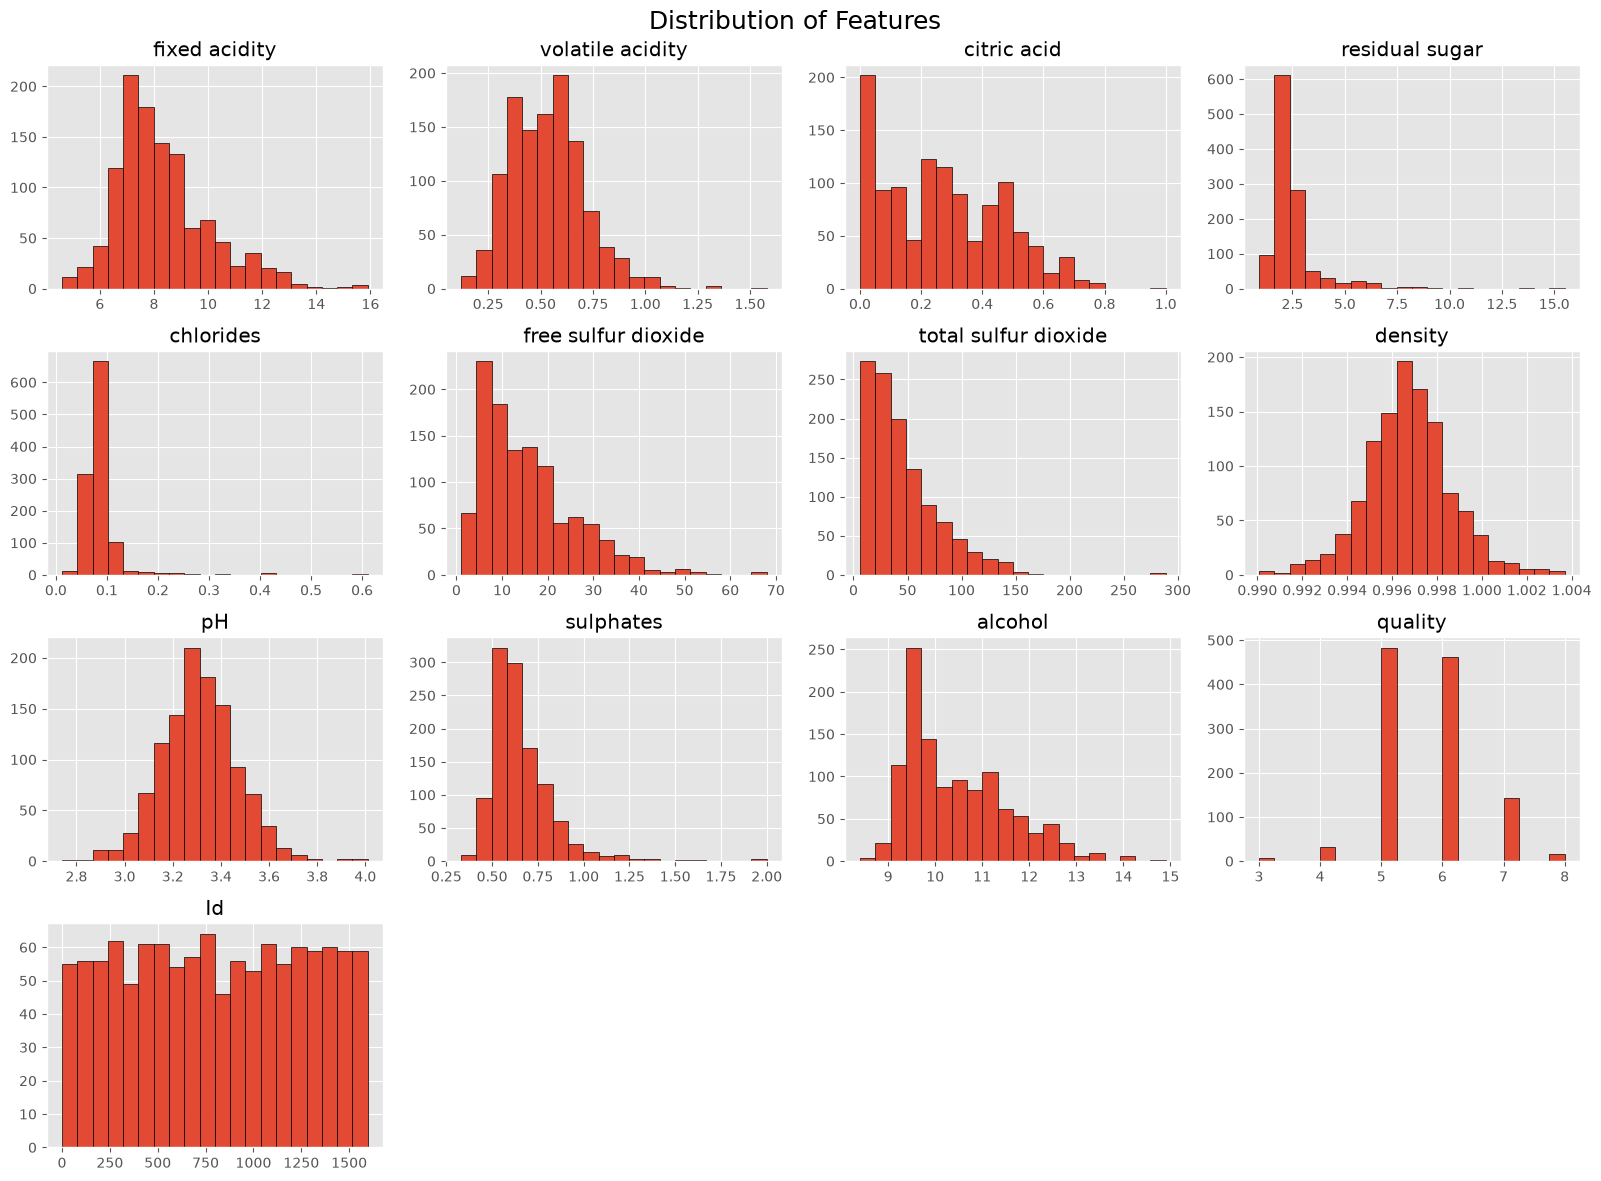

In [11]:
df.hist(
    figsize=(16,12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Features", fontsize=18)

plt.tight_layout()

plt.show()

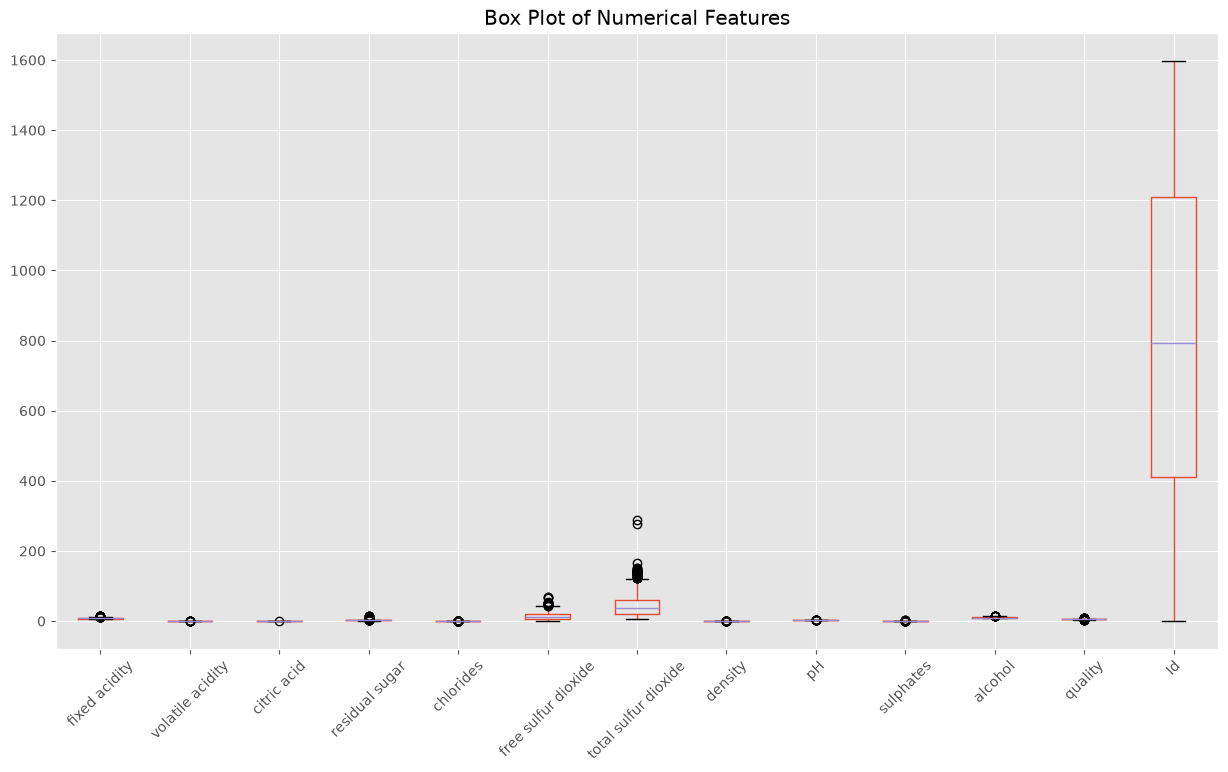

In [12]:
numeric_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(15,8))
df[numeric_cols].boxplot(rot=45)
plt.title("Box Plot of Numerical Features")
plt.show()

In [13]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

fixed acidity: 44 outliers
volatile acidity: 14 outliers
citric acid: 1 outliers
residual sugar: 110 outliers
chlorides: 77 outliers
free sulfur dioxide: 18 outliers
total sulfur dioxide: 40 outliers
density: 36 outliers
pH: 20 outliers
sulphates: 43 outliers
alcohol: 12 outliers
quality: 22 outliers
Id: 0 outliers


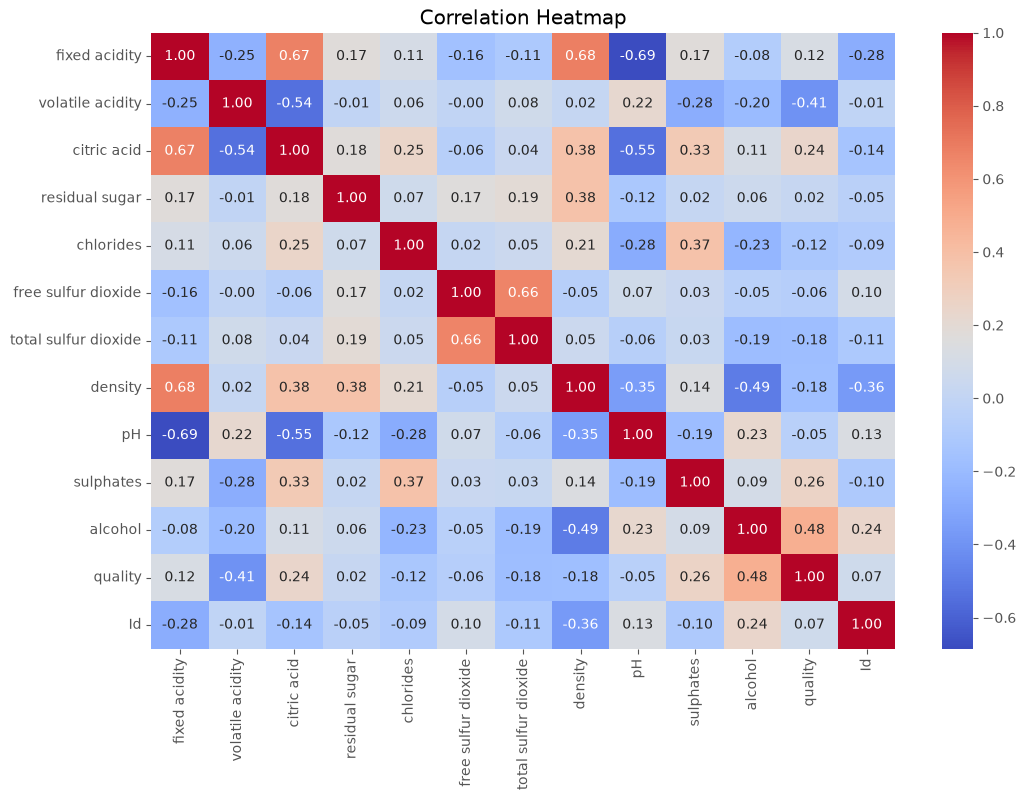

In [14]:

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
X = df.drop("quality", axis=1)

# Target variable
y = df["quality"]

print("Shape of X :", X.shape)
print("Shape of y :", y.shape)

Shape of X : (1143, 12)
Shape of y : (1143,)


In [16]:
scaler = StandardScaler()

# Fit and transform the data
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for better readability
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("Standardization Completed.")

X_scaled.head()

Standardization Completed.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382,-1.735618
1,-0.292593,1.941813,-1.365027,0.050060,0.234247,0.915920,0.643477,0.036165,-0.708928,0.130881,-0.593601,-1.733462
2,-0.292593,1.273492,-1.161568,-0.171289,0.107253,-0.060071,0.246745,0.140103,-0.325775,-0.045254,-0.593601,-1.731306
3,1.653789,-1.399789,1.483400,-0.466421,-0.252560,0.135127,0.429852,0.659792,-0.964363,-0.456235,-0.593601,-1.729150
4,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382,-1.726993


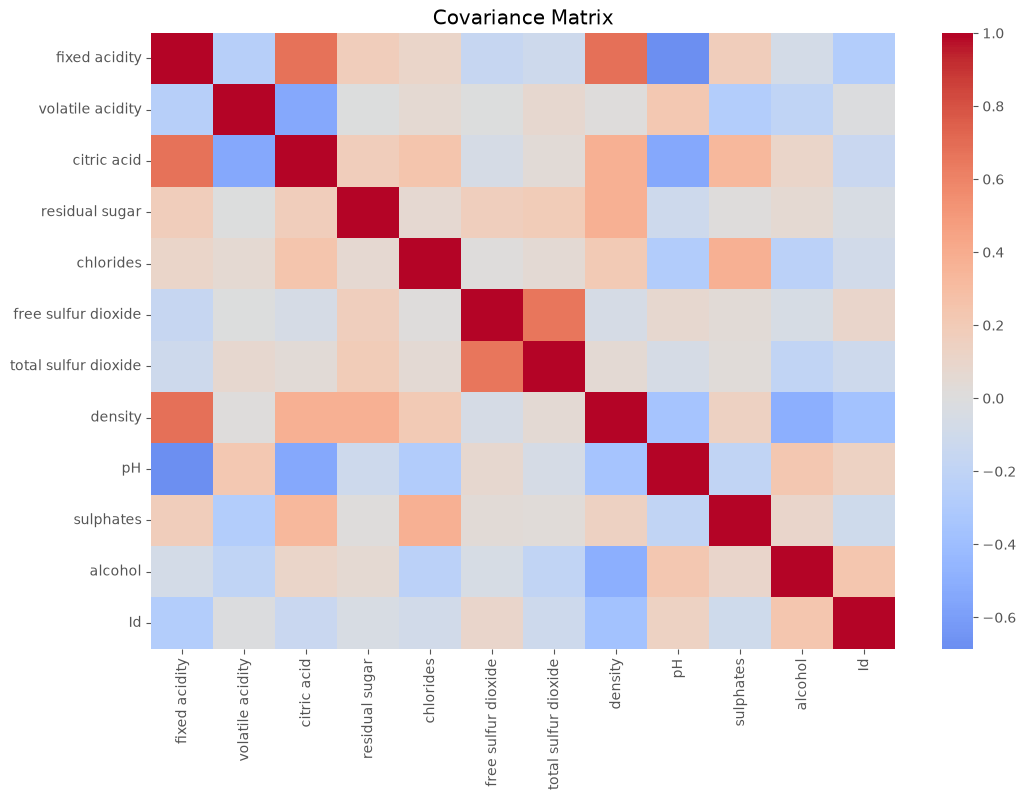

In [17]:
cov_matrix = X_scaled.cov()

plt.figure(figsize=(12,8))

sns.heatmap(
    cov_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Covariance Matrix")

plt.show()

In [18]:
pca = PCA()

# Fit PCA on standardized data
X_pca = pca.fit_transform(X_scaled)

print("PCA Applied Successfully.")

print("Shape after PCA :", X_pca.shape)

PCA Applied Successfully.
Shape after PCA : (1143, 12)


In [19]:
explained_variance = pca.explained_variance_ratio_

variance_df = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(explained_variance))],
    "Explained Variance Ratio": explained_variance
})

variance_df

,Principal Component,Explained Variance Ratio
0,PC1,0.271944
1,PC2,0.158721
2,PC3,0.135854
3,PC4,0.100962
4,PC5,0.080464
5,PC6,0.074491
6,PC7,0.051880
7,PC8,0.044672
8,PC9,0.034801
9,PC10,0.027017


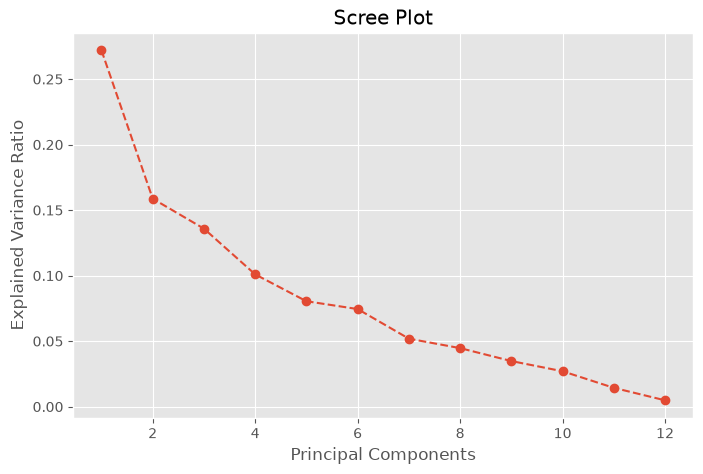

In [20]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(explained_variance)+1),
    explained_variance,
    marker='o',
    linestyle='--'
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")

plt.grid(True)

plt.show()

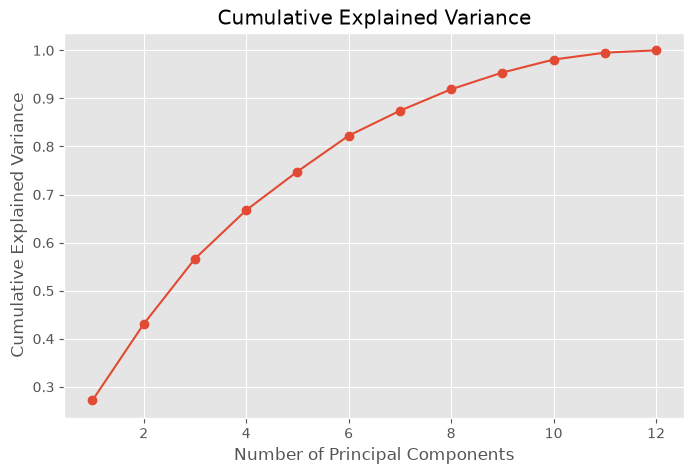

[0.27194409 0.43066498 0.56651872 0.66748038 0.74794465 0.82243568
 0.8743153  0.91898726 0.9537881  0.98080482 0.99516146 1.        ]


In [21]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(cumulative_variance)+1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("Cumulative Explained Variance")

plt.grid(True)

plt.show()

print(cumulative_variance)

In [22]:
threshold = 0.95

n_components_95 = np.argmax(cumulative_variance >= threshold) + 1

print("Number of components needed for 95% variance:", n_components_95)

Number of components needed for 95% variance: 9


In [23]:
pca = PCA(n_components=2)

# Transform the standardized data
X_pca = pca.fit_transform(X_scaled)

print("Original Shape :", X_scaled.shape)
print("Reduced Shape :", X_pca.shape)

Original Shape : (1143, 12)
Reduced Shape : (1143, 2)


In [24]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Add target variable
pca_df["quality"] = y.values

pca_df.head()

,PC1,PC2,quality
0,-1.078814,1.033899,5
1,-0.307332,2.289875,5
2,-0.265776,1.348870,5
3,2.617729,-0.099643,6
4,-1.080670,1.032473,5


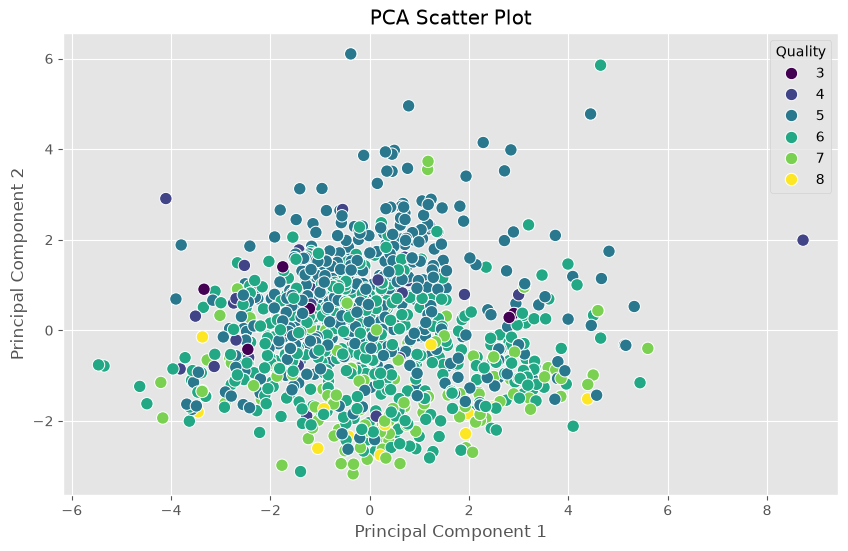

In [25]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="quality",
    palette="viridis",
    s=80
)

plt.title("PCA Scatter Plot")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.legend(title="Quality")

plt.show()

In [26]:
print("Explained Variance Ratio")

print()

print("PC1 :", pca.explained_variance_ratio_[0])

print("PC2 :", pca.explained_variance_ratio_[1])

print()

print("Total Variance Explained :",
      np.sum(pca.explained_variance_ratio_))

Explained Variance Ratio

PC1 : 0.2719440861022282
PC2 : 0.15872089192863964

Total Variance Explained : 0.43066497803086784


In [27]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns
)

loadings

,PC1,PC2
fixed acidity,0.476593,-0.114893
volatile acidity,-0.204295,0.342102
citric acid,0.437978,-0.200551
residual sugar,0.168989,0.217297
chlorides,0.219808,0.133251
free sulfur dioxide,-0.050271,0.455961
total sulfur dioxide,0.025591,0.536663
density,0.409653,0.231536
pH,-0.417033,0.025853
sulphates,0.227146,-0.100847


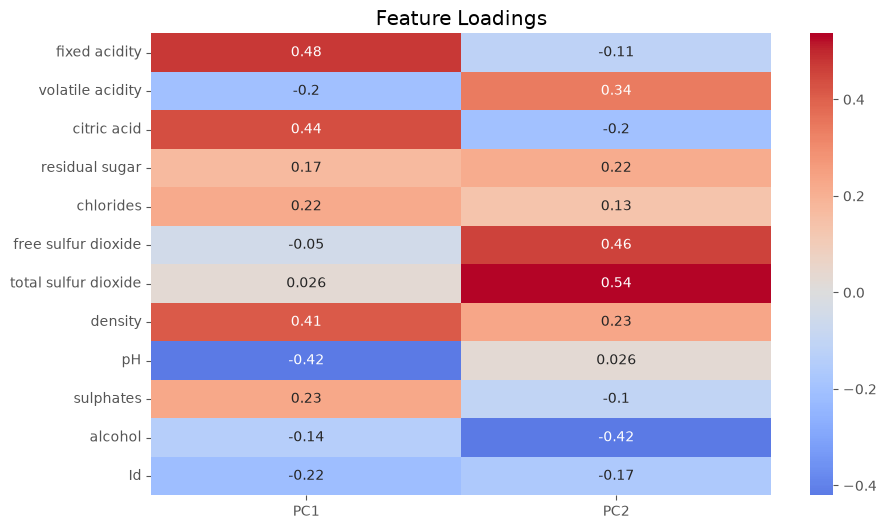

In [28]:
plt.figure(figsize=(10,6))

sns.heatmap(
    loadings,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Loadings")

plt.show()

# Viva / Interview Questions

### 1. What is PCA?
PCA (Principal Component Analysis) is an unsupervised dimensionality reduction technique that transforms correlated variables into a smaller set of uncorrelated variables called principal components.

---

### 2. Why do we use PCA?
- Reduce dimensions
- Remove multicollinearity
- Speed up machine learning models
- Improve visualization

---

### 3. Is PCA supervised or unsupervised?
Unsupervised.

---

### 4. Why is standardization required before PCA?
Because PCA is based on variance. Features with larger scales dominate the principal components if data is not standardized.

---

### 5. What is a Principal Component?
A principal component is a new feature formed as a linear combination of the original features.

---

### 6. What is Explained Variance Ratio?
It is the proportion of the dataset's total variance explained by each principal component.

---

### 7. What is a Scree Plot?
A graph showing the explained variance for each principal component, used to determine how many components to keep.

---

### 8. What are Feature Loadings?
Feature loadings indicate how much each original feature contributes to each principal component.

---

### 9. Can PCA handle categorical variables?
No. PCA works only with numerical features.

---

### 10. What is the biggest disadvantage of PCA?
Loss of interpretability, as principal components are combinations of original variables rather than directly meaningful features.